Listage des fichiers...
Recherche d'images > 512px parmi 481082 fichiers...
Trouvé 4 grandes images. Affichage...


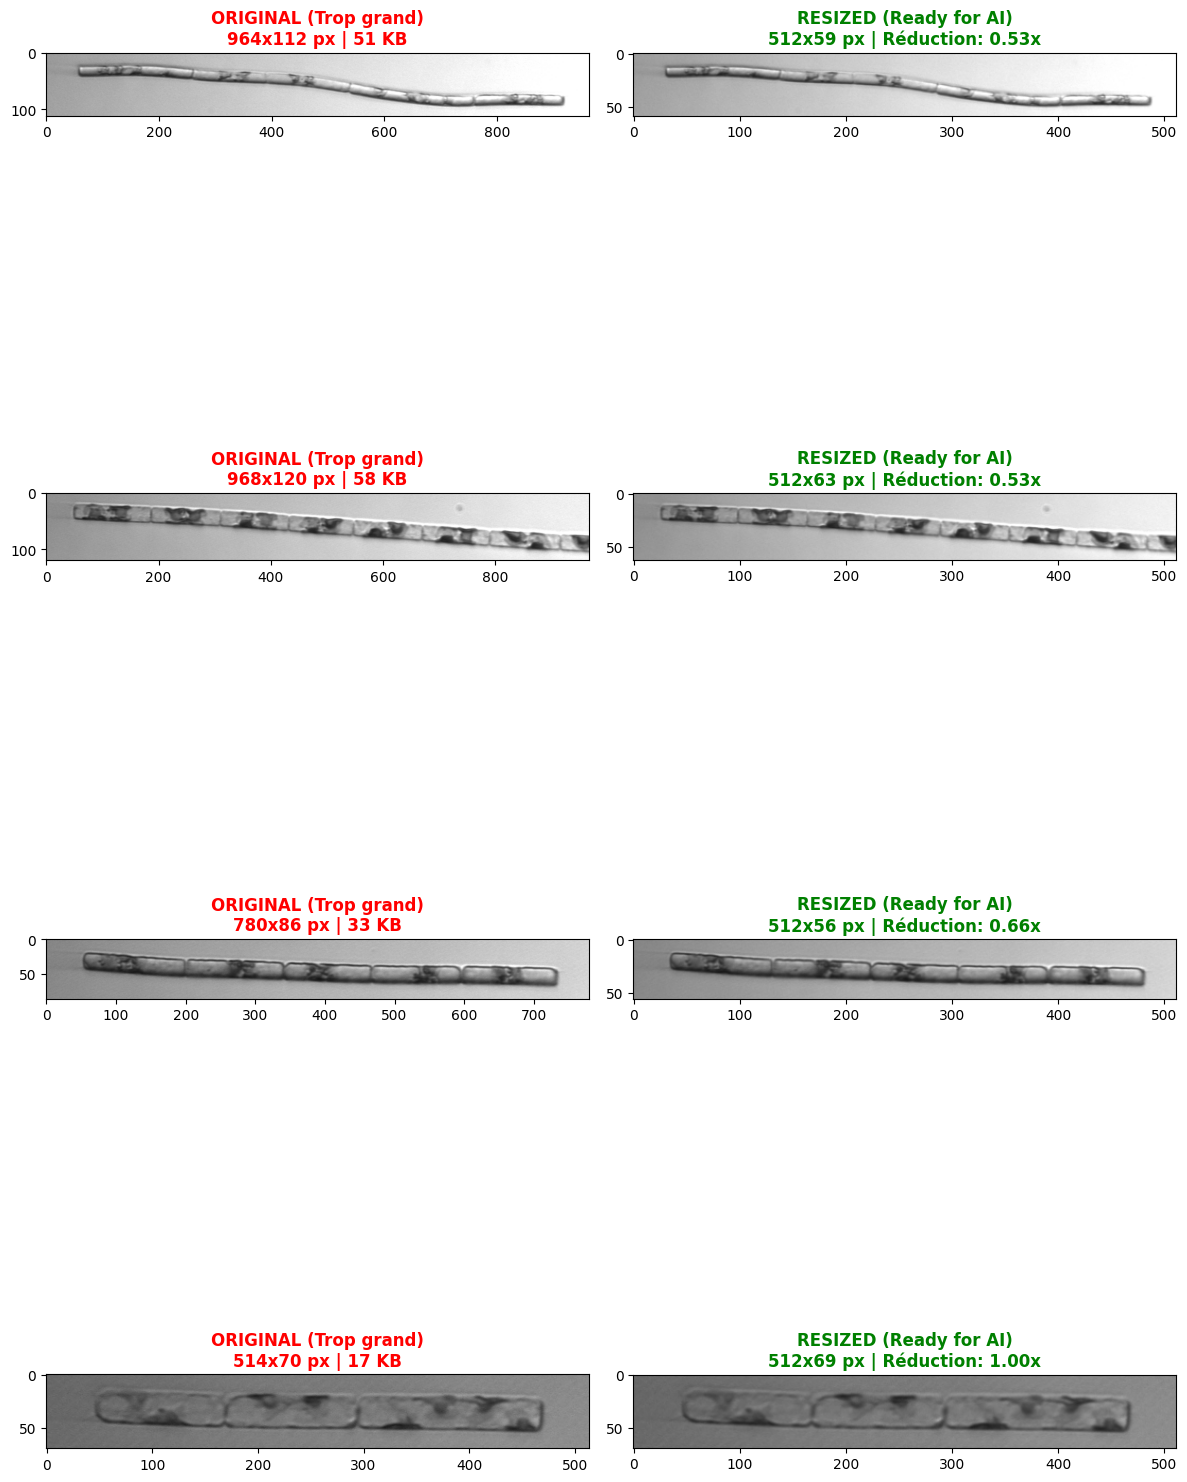

In [4]:
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# === CONFIGURATION ===
# INPUT_DIR = "/home/lmalerba/projects/sdim_data_challenge/kaggle_challenge_sdi_cleaned/kaggle_challenge_sdi/data/pelgas_dataset_cropped/101141/individual_images"
INPUT_DIR = "/home/lmalerba/projects/sdim_data_challenge/kaggle_challenge_sdi_cleaned/kaggle_challenge_sdi/data/whoi_dataset"
TARGET_SIZE = 512 
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

def get_large_samples(root_dir, n=4, min_size=512):
    """
    Cherche spécifiquement des images plus grandes que min_size.
    On mélange la liste des fichiers pour ne pas toujours tomber sur les mêmes.
    """
    root_path = Path(root_dir)
    all_files = []
    print("Listage des fichiers...")
    for ext in EXTENSIONS:
        all_files.extend(list(root_path.rglob(f"*{ext}")))
    
    # On mélange pour avoir de la variété
    random.shuffle(all_files)
    
    found_images = []
    print(f"Recherche d'images > {min_size}px parmi {len(all_files)} fichiers...")
    
    # On parcourt jusqu'à trouver n images géantes
    for f in all_files:
        # On lit juste les dimensions pour aller vite (sans décoder tout les pixels si possible)
        # Mais cv2 lit tout, c'est robuste.
        img = cv2.imread(str(f))
        if img is None: continue
        
        h, w = img.shape[:2]
        
        # CONDITION DE FILTRE : Il faut que ça dépasse la cible
        if max(h, w) > min_size:
            found_images.append(f)
            
        if len(found_images) >= n:
            break
            
    return found_images

def resize_longest_edge(img, target_size=512):
    """Redimensionne en gardant le ratio, max edge = target_size"""
    h, w = img.shape[:2]
    
    scale = target_size / max(h, w)
    new_w = int(w * scale)
    new_h = int(h * scale)
    
    # INTER_AREA réduit le moiré/bruit lors du rapetissement
    resized_img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    return resized_img, scale

# === EXÉCUTION ===
# On cherche 4 images qui sont VRAIMENT grandes
samples = get_large_samples(INPUT_DIR, n=4, min_size=TARGET_SIZE)

if not samples:
    print(f"Aucune image supérieure à {TARGET_SIZE}px n'a été trouvée (ou dataset trop petit).")
else:
    print(f"Trouvé {len(samples)} grandes images. Affichage...")
    fig, axes = plt.subplots(len(samples), 2, figsize=(12, 5 * len(samples)))
    if len(samples) == 1: axes = [axes] # Gestion cas unique

    for i, file_path in enumerate(samples):
        # Lecture
        img_bgr = cv2.imread(str(file_path))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        
        # Resize
        img_resized, scale = resize_longest_edge(img_rgb, TARGET_SIZE)
        
        # --- Affichage AVANT ---
        h, w = img_rgb.shape[:2]
        size_kb_orig = os.path.getsize(file_path) / 1024
        
        # On affiche l'original
        axes[i][0].imshow(img_rgb)
        axes[i][0].set_title(f"ORIGINAL (Trop grand)\n{w}x{h} px | {size_kb_orig:.0f} KB", color='red', fontweight='bold')
        axes[i][0].axis('on')
        
        # --- Affichage APRÈS ---
        h_r, w_r = img_resized.shape[:2]
        # Estimation poids
        size_kb_res = (img_resized.nbytes) / 1024 / 7 # Approximation compression JPG
        
        axes[i][1].imshow(img_resized)
        axes[i][1].set_title(f"RESIZED (Ready for AI)\n{w_r}x{h_r} px | Réduction: {scale:.2f}x", color='green', fontweight='bold')
        axes[i][1].axis('on')

    plt.tight_layout()
    plt.show()

